In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import scvelo  ## For mouse gastrulation data 
import anndata
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(8,8) #rescale figures
sc.settings.verbosity = 3

import milopy.core as milo
import milopy.plot as milopl

In [3]:
denovo_recalc = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_denovo.h5ad")
denovo_ref = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_denovo_ref_hvg.h5ad")
scarches_unlabeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_scArches_full.h5ad")
scarches_labeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_scArches_labeled_full.h5ad")
atlas_data = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/atlas_data.h5ad")

In [5]:
query_studies = ['Banovich_Kropski_2020', 'Kaminski_2020', 'Misharin_Budinger_2018', 'Sheppard_2020']

# 1. De-Novo with recalculated HVGs

In [6]:
denovo_recalc.obs["origin"] = "reference"
denovo_recalc.obs.loc[denovo_recalc.obs.study.isin(query_studies),"origin"] = "query"

In [7]:
del(denovo_recalc.uns)
del(denovo_recalc.obsp)
denovo_recalc.var = denovo_recalc.var.loc[:,["highly_variable"]]
del(denovo_recalc.obsm["X_umap_unintegrated"])
denovo_recalc.X = np.nan_to_num(denovo_recalc.X)

In [8]:
denovo_recalc.obs = denovo_recalc.obs.loc[:,["sample","study","dataset","origin","scanvi_label"]]

In [10]:
sc.pp.neighbors(denovo_recalc, n_neighbors=50, n_pcs=30, use_rep="X_scANVI")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:11:16)


In [11]:
sc.tl.umap(denovo_recalc)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:26:04)


... storing 'origin' as categorical


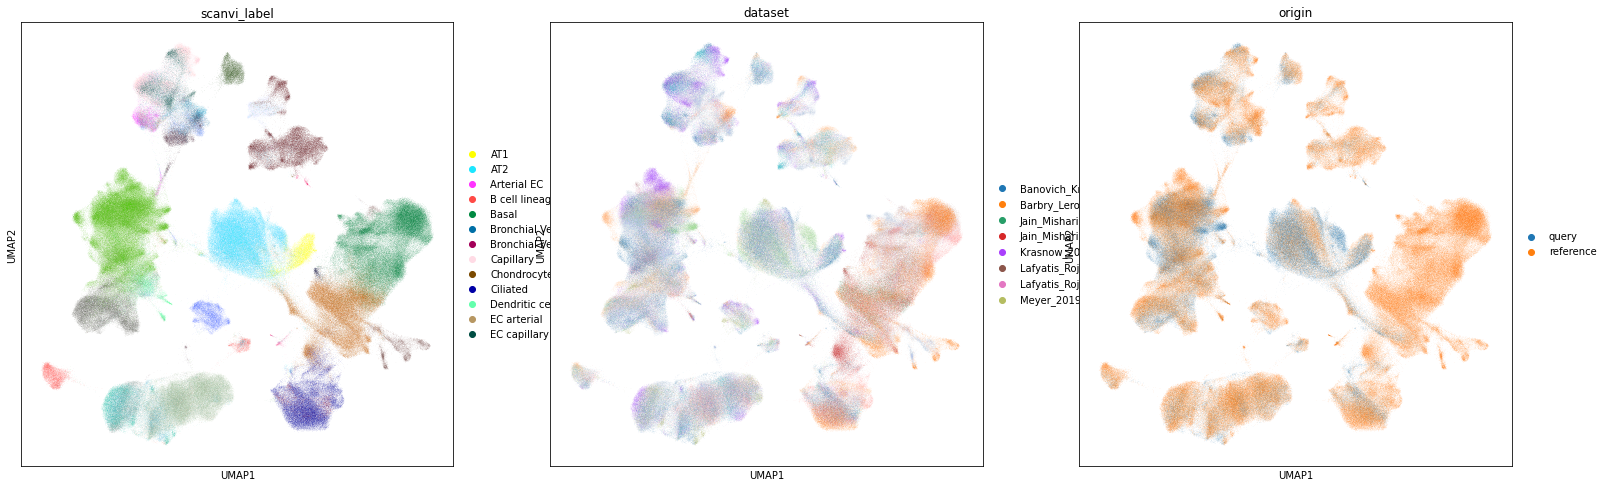

In [12]:
sc.pl.umap(denovo_recalc, color=["scanvi_label","dataset", "origin"])

In [13]:
milo.make_nhoods(denovo_recalc, prop=0.1)

In [14]:
denovo_recalc.obsm["nhoods"]

<713512x51329 sparse matrix of type '<class 'numpy.float32'>'
	with 6130647 stored elements in Compressed Sparse Row format>

In [15]:
denovo_recalc[denovo_recalc.obs['nhood_ixs_refined'] != 0].obs[['nhood_ixs_refined', 'nhood_kth_distance']]

,nhood_ixs_refined,nhood_kth_distance
AGCGGTCGTCTCTCTG_SC22-0,1,1.077721
D354_Biop_Pro1_ACGGCCACACAGCCCA-1-20-0,1,1.098527
GTTCGGGAGAAACCAT_F01874-0,1,1.796363
D367_Biop_Pro1_TGTGTTTAGTTCCACA-1-28-0,1,1.036582
P2_6_TGAGAGGAGAGTAAGG-0,1,1.557306
...,...,...
TTTCCTCAGATCCTGT-HCATisStab7732262-1,1,1.108521
TTTGCGCCACGCCAGT-HCATisStab7732262-1,1,1.982422
TTTGGTTTCAAGATCC-HCATisStab7732262-1,1,1.332288
TTTGTCACACACCGCA-HCATisStab7732262-1,1,1.156039


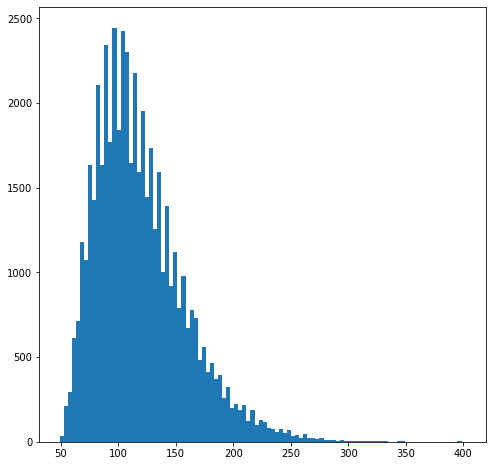

In [16]:
nhood_size = np.array(denovo_recalc.obsm["nhoods"].sum(0)).ravel()
plt.hist(nhood_size, bins=100);

In [17]:
milo.count_nhoods(denovo_recalc, sample_col="sample")

In [20]:
denovo_recalc.uns["nhood_adata"]

AnnData object with n_obs × n_vars = 51329 × 225
    obs: 'index_cell', 'kth_distance'
    uns: 'sample_col'

In [23]:
denovo_recalc.obs["origin_continuous"] = denovo_recalc.obs["origin"].cat.codes

In [29]:
milo.DA_nhoods(denovo_recalc, design="~origin_continuous")

In [30]:
denovo_recalc.uns["nhood_adata"].obs

,index_cell,kth_distance,logFC,logCPM,F,PValue,FDR,SpatialFDR
0,AGCGGTCGTCTCTCTG_SC22-0,1.077721,-5.047196,7.417403,151.240794,6.435130e-30,2.820741e-28,2.785708e-28
1,D354_Biop_Pro1_ACGGCCACACAGCCCA-1-20-0,1.098527,2.576814,7.016369,39.691105,8.608923e-10,3.794654e-09,3.587357e-09
2,GTTCGGGAGAAACCAT_F01874-0,1.796363,-2.988158,7.094264,54.385118,8.850759e-13,8.420771e-12,8.453391e-12
3,D367_Biop_Pro1_TGTGTTTAGTTCCACA-1-28-0,1.036582,2.806143,7.071885,39.102417,1.129932e-09,4.579414e-09,4.339948e-09
4,P2_6_TGAGAGGAGAGTAAGG-0,1.557306,-1.040075,6.929342,6.171491,3.594980e-02,4.865442e-02,4.846365e-02
...,...,...,...,...,...,...,...,...
51324,TTTCCTCAGATCCTGT-HCATisStab7732262-1,1.108521,2.041963,7.332639,12.280073,5.078433e-04,8.707897e-04,8.680047e-04
51325,TTTGCGCCACGCCAGT-HCATisStab7732262-1,1.982422,2.866340,7.098260,40.580805,7.569710e-10,3.469171e-09,3.278685e-09
51326,TTTGGTTTCAAGATCC-HCATisStab7732262-1,1.332288,-0.009298,7.022308,0.003118,9.554987e-01,9.663427e-01,9.661627e-01
51327,TTTGTCACACACCGCA-HCATisStab7732262-1,1.156039,0.408742,7.273753,0.600944,6.331113e-01,6.866331e-01,6.859632e-01


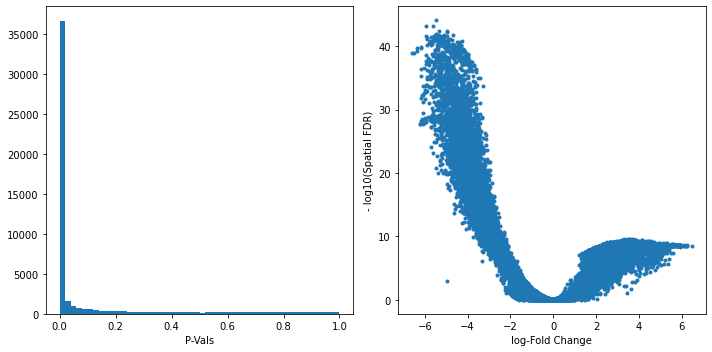

In [31]:
old_figsize = plt.rcParams["figure.figsize"]
plt.rcParams["figure.figsize"] = [10,5]
plt.subplot(1,2,1)
plt.hist(denovo_recalc.uns["nhood_adata"].obs.PValue, bins=50);
plt.xlabel("P-Vals");
plt.subplot(1,2,2)
plt.plot(denovo_recalc.uns["nhood_adata"].obs.logFC, -np.log10(denovo_recalc.uns["nhood_adata"].obs.SpatialFDR), '.');
plt.xlabel("log-Fold Change");
plt.ylabel("- log10(Spatial FDR)");
plt.tight_layout()
plt.rcParams["figure.figsize"] = old_figsize

In [32]:
import milopy.utils
milopy.utils.build_nhood_graph(denovo_recalc)

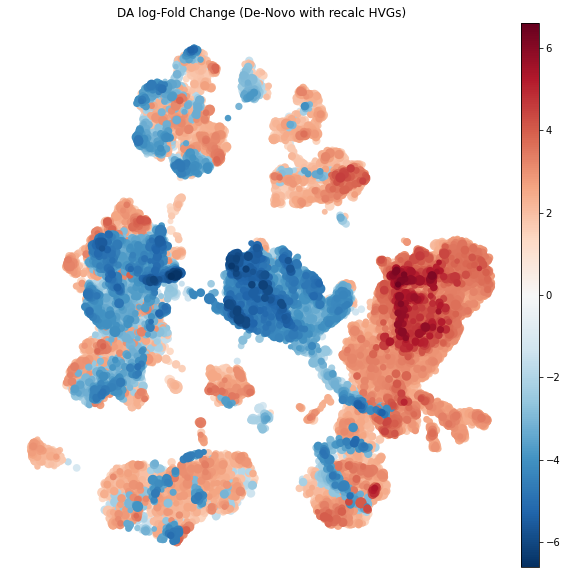

In [65]:
plt.rcParams["figure.figsize"] = [10,10]
milopl.plot_nhood_graph(denovo_recalc, 
                        alpha=0.01, ## SpatialFDR level (1%) 
                        min_size=2, ## Size of smallest dot
                        title="DA log-Fold Change (De-Novo with recalc HVGs)"
                       )

In [35]:
milopy.utils.annotate_nhoods(denovo_recalc, anno_col='scanvi_label')

Text(0.5, 0, 'celltype fraction')

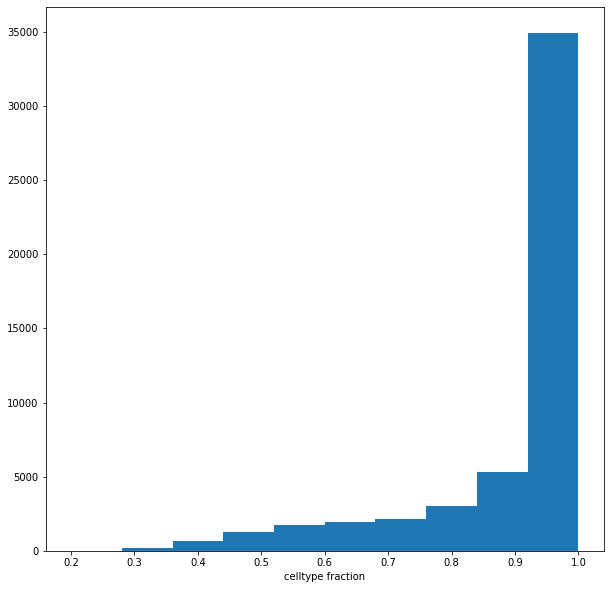

In [37]:
plt.hist(denovo_recalc.uns['nhood_adata'].obs["nhood_annotation_frac"]);
plt.xlabel("celltype fraction")

In [38]:
denovo_recalc.uns['nhood_adata'].obs.loc[denovo_recalc.uns['nhood_adata'].obs["nhood_annotation_frac"] < 0.6, "nhood_annotation"] = "Mixed"

... storing 'nhood_annotation' as categorical


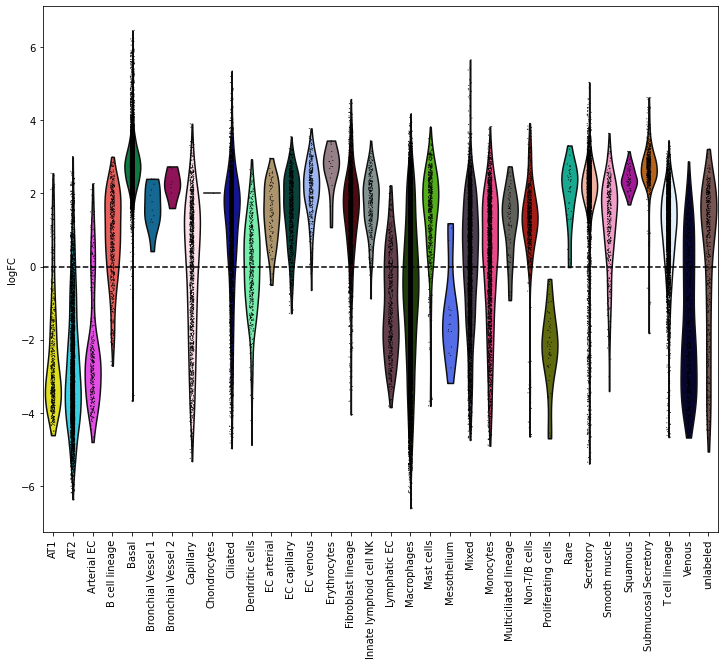

In [39]:
sc.pl.violin(denovo_recalc.uns['nhood_adata'], "logFC", groupby="nhood_annotation", rotation=90, show=False);
plt.axhline(y=0, color='black', linestyle='--');
plt.show()

# 2. unlabeled scArches

In [40]:
scarches_unlabeled.obs["origin"] = "reference"
scarches_unlabeled.obs.loc[scarches_unlabeled.obs.study.isin(query_studies),"origin"] = "query"

In [42]:
scarches_unlabeled.obs = scarches_unlabeled.obs.loc[:,["sample","study","dataset","origin","scanvi_label"]]

In [45]:
sc.pp.neighbors(scarches_unlabeled, n_neighbors=50, n_pcs=30, use_rep="X_scArches")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:10:31)


In [46]:
sc.tl.umap(scarches_unlabeled)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:28:33)


... storing 'origin' as categorical


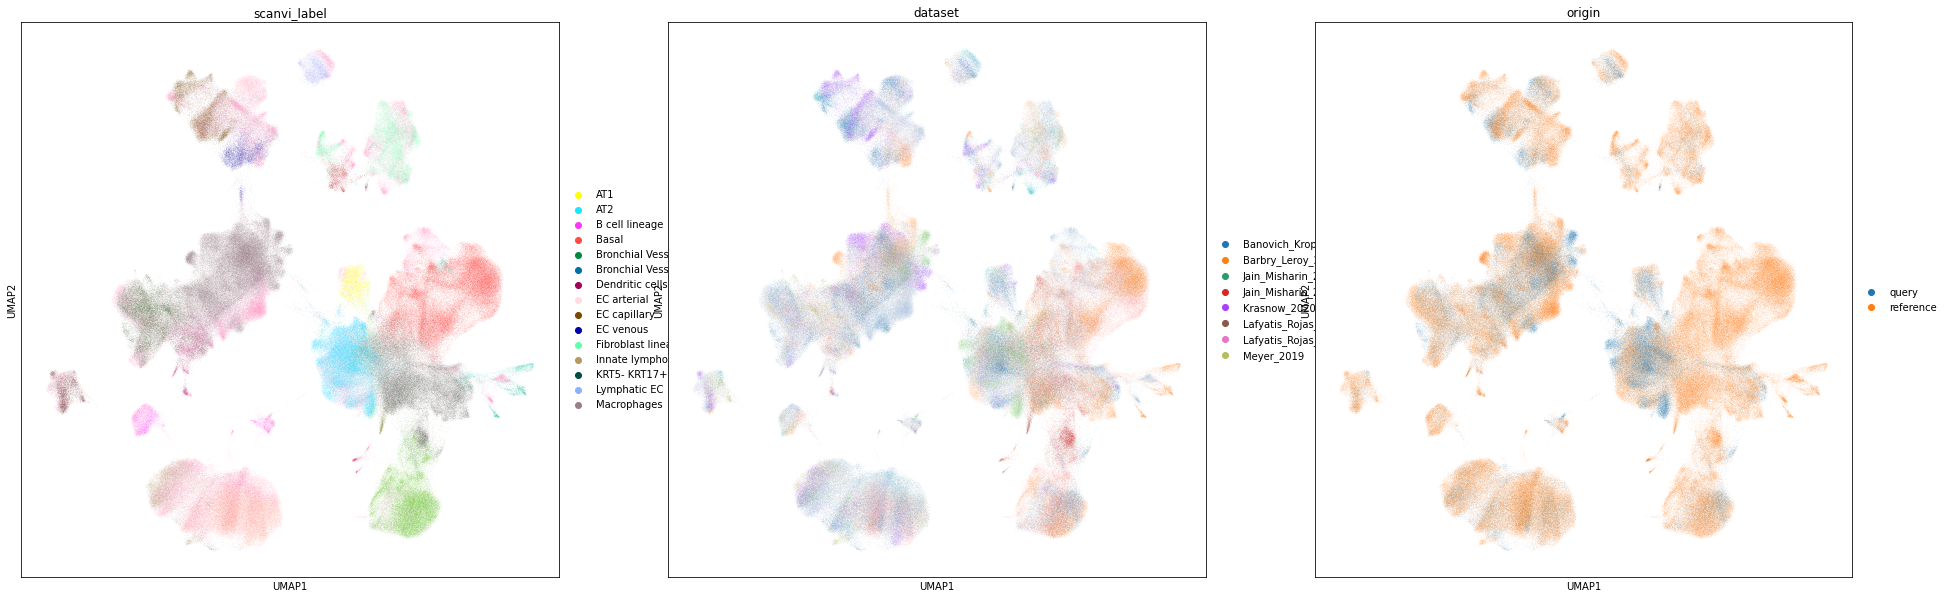

In [47]:
sc.pl.umap(scarches_unlabeled, color=["scanvi_label","dataset", "origin"])

In [48]:
milo.make_nhoods(scarches_unlabeled, prop=0.1)

In [49]:
scarches_unlabeled.obsm["nhoods"]

<713512x50370 sparse matrix of type '<class 'numpy.float32'>'
	with 6220070 stored elements in Compressed Sparse Row format>

In [50]:
scarches_unlabeled[scarches_unlabeled.obs['nhood_ixs_refined'] != 0].obs[['nhood_ixs_refined', 'nhood_kth_distance']]

,nhood_ixs_refined,nhood_kth_distance
GCTCCTAAGTGGACGT-1-HCATisStab7659969-0,1,1.553917
CTACCCAAGGCTCTCG_SC85-0,1,1.247587
AGTTGGTTCGGCCGAT_F01641-0,1,1.261280
ATCACGACAACACCTA-1-1-0,1,1.522238
TAAGTGCCAATACGCT_GRO-03_biopsy-0,1,1.599116
...,...,...
TTGCCGTTCAGAGACG-HCATisStab7732262-1,1,1.647742
TTTCCTCAGATCCTGT-HCATisStab7732262-1,1,1.587508
TTTGTCAAGTGTCCAT-HCATisStab7732262-1,1,1.467898
TTTGTCAGTACAGCAG-HCATisStab7732262-1,1,1.524074


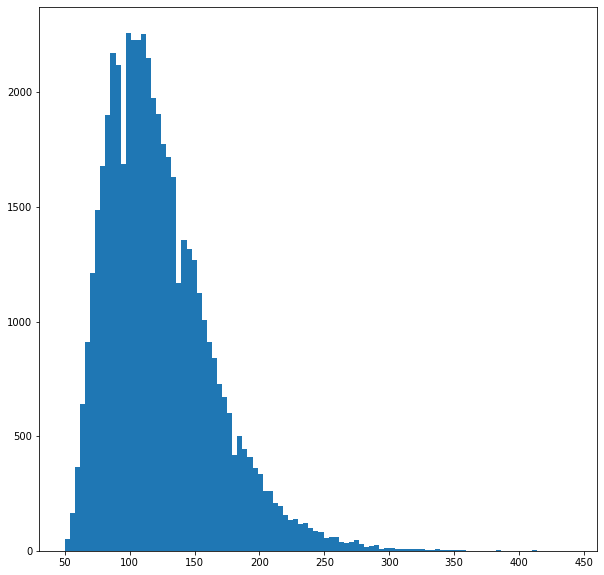

In [51]:
nhood_size = np.array(scarches_unlabeled.obsm["nhoods"].sum(0)).ravel()
plt.hist(nhood_size, bins=100);

In [52]:
milo.count_nhoods(scarches_unlabeled, sample_col="sample")

In [53]:
scarches_unlabeled.uns["nhood_adata"]

AnnData object with n_obs × n_vars = 50370 × 225
    obs: 'index_cell', 'kth_distance'
    uns: 'sample_col'

In [54]:
scarches_unlabeled.obs["origin_continuous"] = scarches_unlabeled.obs["origin"].cat.codes

In [55]:
milo.DA_nhoods(scarches_unlabeled, design="~origin_continuous")

In [56]:
scarches_unlabeled.uns["nhood_adata"].obs

,index_cell,kth_distance,logFC,logCPM,F,PValue,FDR,SpatialFDR
0,GCTCCTAAGTGGACGT-1-HCATisStab7659969-0,1.553917,1.345425,7.157417,8.436133,3.854337e-03,6.031157e-03,6.052309e-03
1,CTACCCAAGGCTCTCG_SC85-0,1.247587,0.136194,7.113611,0.097395,7.551193e-01,7.936103e-01,7.933446e-01
2,AGTTGGTTCGGCCGAT_F01641-0,1.261280,-1.826790,7.672910,11.462814,7.704788e-04,1.321923e-03,1.324124e-03
3,ATCACGACAACACCTA-1-1-0,1.522238,2.024191,7.249382,15.947683,7.571745e-05,1.475963e-04,1.473949e-04
4,TAAGTGCCAATACGCT_GRO-03_biopsy-0,1.599116,1.652628,7.018266,34.348425,3.137892e-08,9.646366e-08,9.368511e-08
...,...,...,...,...,...,...,...,...
50365,TTGCCGTTCAGAGACG-HCATisStab7732262-1,1.647742,0.891564,7.322756,2.694318,1.013856e-01,1.284857e-01,1.288377e-01
50366,TTTCCTCAGATCCTGT-HCATisStab7732262-1,1.587508,1.683174,7.412733,8.498329,3.727095e-03,5.845126e-03,5.865235e-03
50367,TTTGTCAAGTGTCCAT-HCATisStab7732262-1,1.467898,2.878302,7.496861,22.538683,2.749817e-06,6.403822e-06,6.347391e-06
50368,TTTGTCAGTACAGCAG-HCATisStab7732262-1,1.524074,1.791961,7.193997,13.907386,2.158442e-04,3.979675e-04,3.981963e-04


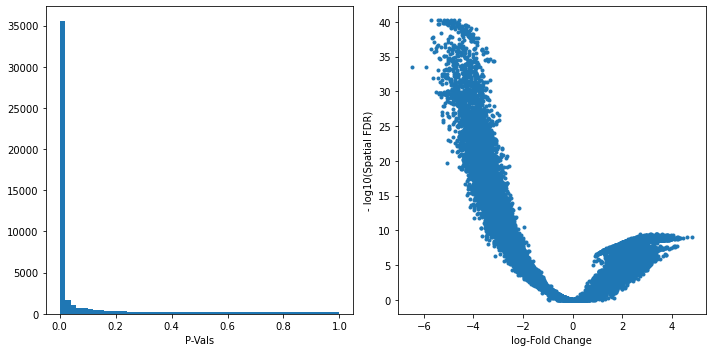

In [57]:
old_figsize = plt.rcParams["figure.figsize"]
plt.rcParams["figure.figsize"] = [10,5]
plt.subplot(1,2,1)
plt.hist(scarches_unlabeled.uns["nhood_adata"].obs.PValue, bins=50);
plt.xlabel("P-Vals");
plt.subplot(1,2,2)
plt.plot(scarches_unlabeled.uns["nhood_adata"].obs.logFC, -np.log10(scarches_unlabeled.uns["nhood_adata"].obs.SpatialFDR), '.');
plt.xlabel("log-Fold Change");
plt.ylabel("- log10(Spatial FDR)");
plt.tight_layout()
plt.rcParams["figure.figsize"] = old_figsize

In [58]:
import milopy.utils
milopy.utils.build_nhood_graph(scarches_unlabeled)

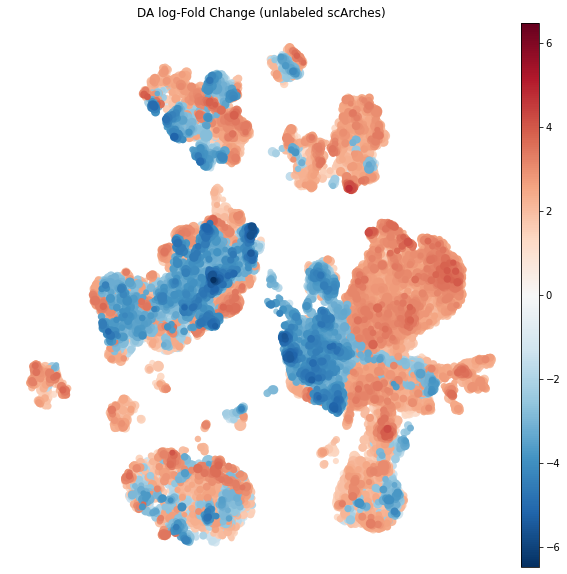

In [66]:
plt.rcParams["figure.figsize"] = [10,10]
milopl.plot_nhood_graph(scarches_unlabeled, 
                        alpha=0.01, ## SpatialFDR level (1%) 
                        min_size=2, ## Size of smallest dot
                        title="DA log-Fold Change (unlabeled scArches)"
                       )

In [60]:
milopy.utils.annotate_nhoods(scarches_unlabeled, anno_col='scanvi_label')

Text(0.5, 0, 'celltype fraction')

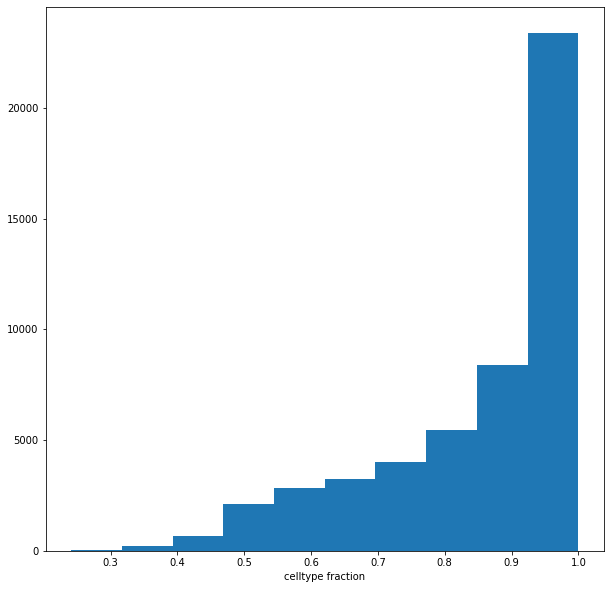

In [61]:
plt.hist(scarches_unlabeled.uns['nhood_adata'].obs["nhood_annotation_frac"]);
plt.xlabel("celltype fraction")

In [62]:
scarches_unlabeled.uns['nhood_adata'].obs.loc[scarches_unlabeled.uns['nhood_adata'].obs["nhood_annotation_frac"] < 0.6, "nhood_annotation"] = "Mixed"

... storing 'nhood_annotation' as categorical


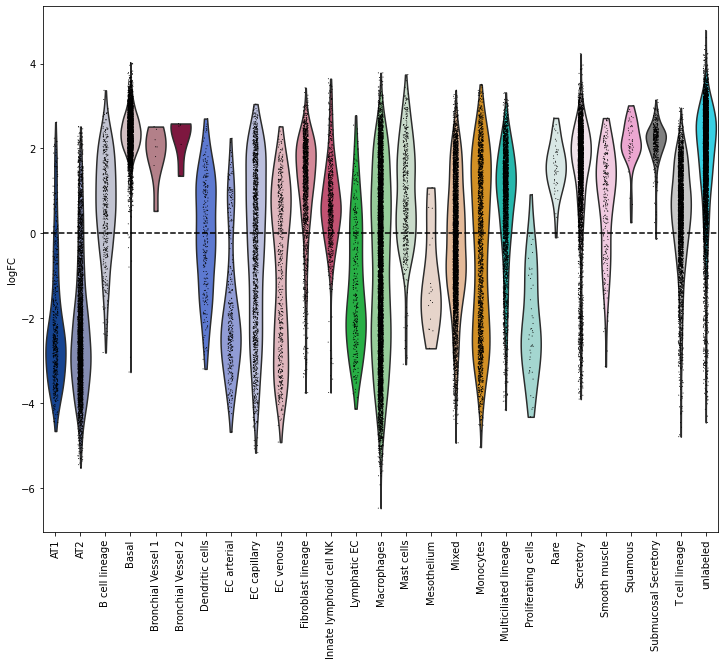

In [63]:
sc.pl.violin(scarches_unlabeled.uns['nhood_adata'], "logFC", groupby="nhood_annotation", rotation=90, show=False);
plt.axhline(y=0, color='black', linestyle='--');
plt.show()

# 3. labeled scArches

In [67]:
scarches_labeled.obs["origin"] = "reference"
scarches_labeled.obs.loc[scarches_labeled.obs.study.isin(query_studies),"origin"] = "query"

In [68]:
scarches_labeled.obs = scarches_labeled.obs.loc[:,["sample","study","dataset","origin","scanvi_label"]]

In [69]:
sc.pp.neighbors(scarches_labeled, n_neighbors=50, n_pcs=30, use_rep="X_scArches")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:10:55)


In [70]:
sc.tl.umap(scarches_labeled)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:27:40)


... storing 'origin' as categorical


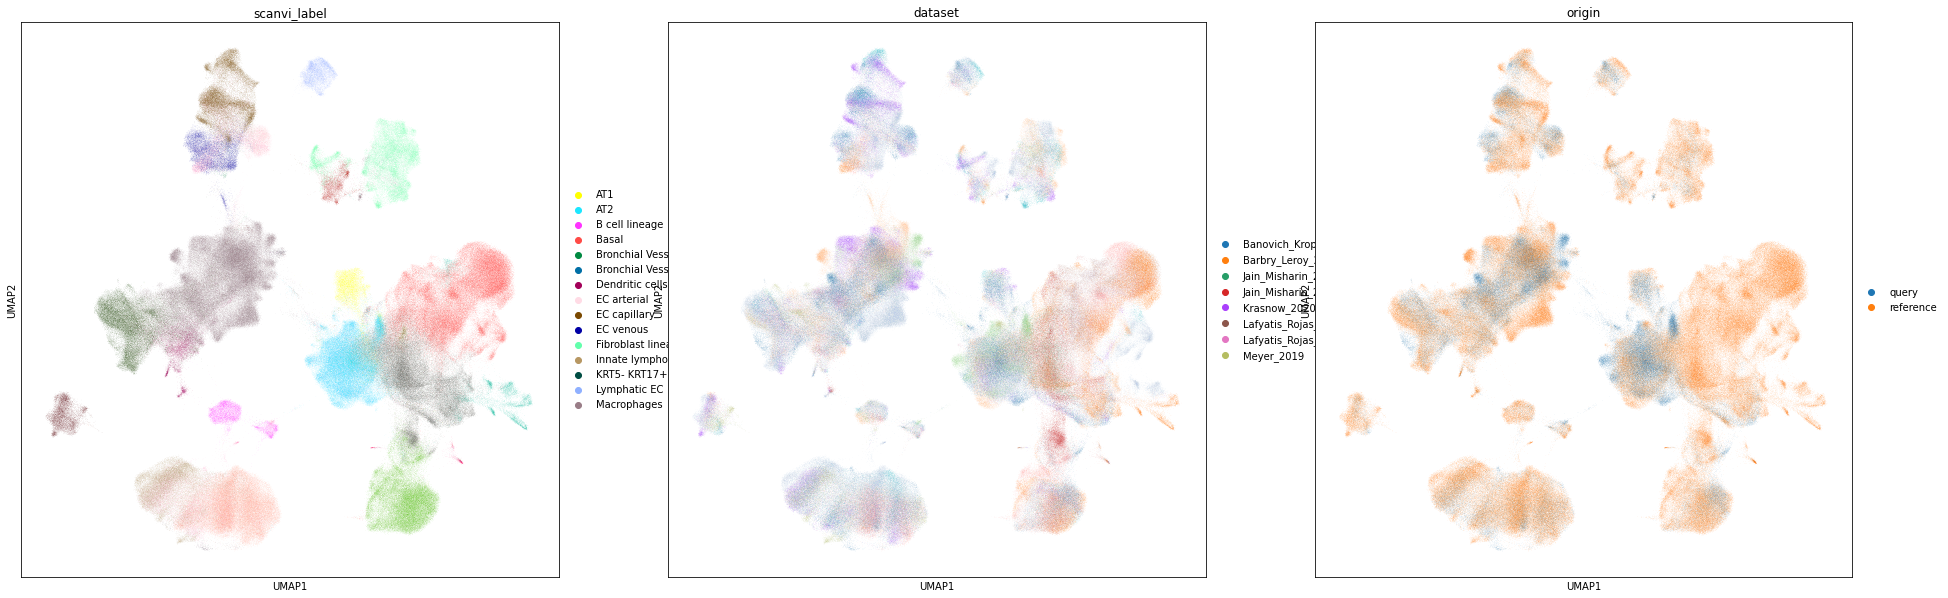

In [71]:
sc.pl.umap(scarches_labeled, color=["scanvi_label","dataset", "origin"])

In [72]:
milo.make_nhoods(scarches_labeled, prop=0.1)

In [73]:
scarches_labeled.obsm["nhoods"]

<713512x50376 sparse matrix of type '<class 'numpy.float32'>'
	with 6209963 stored elements in Compressed Sparse Row format>

In [74]:
scarches_labeled[scarches_labeled.obs['nhood_ixs_refined'] != 0].obs[['nhood_ixs_refined', 'nhood_kth_distance']]

,nhood_ixs_refined,nhood_kth_distance
GCTCCTAAGTGGACGT-1-HCATisStab7659969-0,1,1.550504
CTACCCAAGGCTCTCG_SC85-0,1,1.247587
AGTTGGTTCGGCCGAT_F01641-0,1,1.228052
ACAGCCGGTCCGTTAA_F02526-0,1,1.631861
ATCACGACAACACCTA-1-1-0,1,1.522238
...,...,...
TTCTCAACATCGGTTA-HCATisStab7732262-1,1,1.611342
TTGAACGGTAAGGATT-HCATisStab7732262-1,1,1.428887
TTGCCGTTCAGAGACG-HCATisStab7732262-1,1,1.588714
TTTGCGCTCCAAACTG-HCATisStab7732262-1,1,1.499014


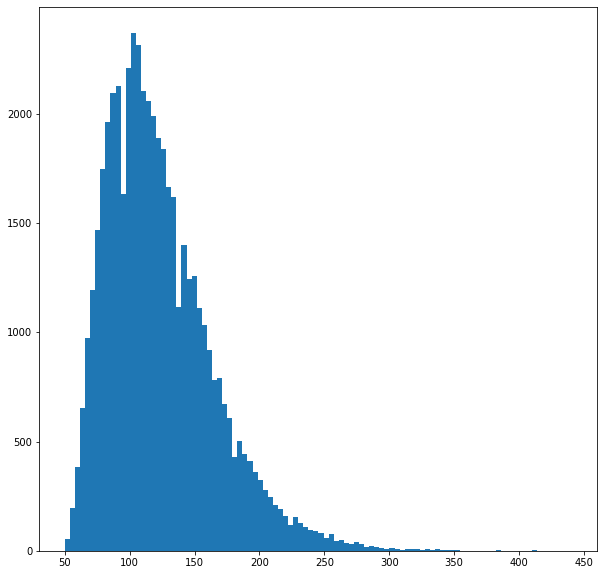

In [75]:
nhood_size = np.array(scarches_labeled.obsm["nhoods"].sum(0)).ravel()
plt.hist(nhood_size, bins=100);

In [76]:
milo.count_nhoods(scarches_labeled, sample_col="sample")

In [77]:
scarches_labeled.uns["nhood_adata"]

AnnData object with n_obs × n_vars = 50376 × 225
    obs: 'index_cell', 'kth_distance'
    uns: 'sample_col'

In [78]:
scarches_labeled.obs["origin_continuous"] = scarches_labeled.obs["origin"].cat.codes

In [ ]:
milo.DA_nhoods(scarches_labeled, design="~origin_continuous")

In [85]:
scarches_labeled.uns["nhood_adata"].obs

,index_cell,kth_distance,logFC,logCPM,F,PValue,FDR,SpatialFDR,Nhood_size
0,GCTCCTAAGTGGACGT-1-HCATisStab7659969-0,1.550504,1.498981,7.180788,9.789986,0.001873,0.002982,0.002990,99.0
1,CTACCCAAGGCTCTCG_SC85-0,1.247587,0.281312,7.121206,0.380946,0.537420,0.586619,0.586877,126.0
2,AGTTGGTTCGGCCGAT_F01641-0,1.228052,-1.549408,7.752015,7.499645,0.006424,0.009557,0.009592,314.0
3,ACAGCCGGTCCGTTAA_F02526-0,1.631861,0.962945,7.218716,3.688592,0.055439,0.072273,0.072512,110.0
4,ATCACGACAACACCTA-1-1-0,1.522238,1.964243,7.228182,15.258585,0.000109,0.000201,0.000201,143.0
...,...,...,...,...,...,...,...,...,...
50371,TTCTCAACATCGGTTA-HCATisStab7732262-1,1.611342,1.895725,7.342436,11.633178,0.000708,0.001190,0.001192,135.0
50372,TTGAACGGTAAGGATT-HCATisStab7732262-1,1.428887,1.724524,7.432642,8.425416,0.003888,0.005951,0.005971,139.0
50373,TTGCCGTTCAGAGACG-HCATisStab7732262-1,1.588714,0.782451,7.268862,2.214871,0.137410,0.168366,0.168832,126.0
50374,TTTGCGCTCCAAACTG-HCATisStab7732262-1,1.499014,1.650703,7.186476,12.184477,0.000531,0.000906,0.000908,95.0


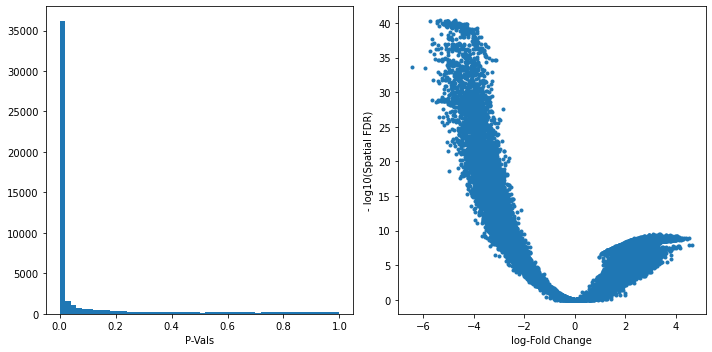

In [86]:
old_figsize = plt.rcParams["figure.figsize"]
plt.rcParams["figure.figsize"] = [10,5]
plt.subplot(1,2,1)
plt.hist(scarches_labeled.uns["nhood_adata"].obs.PValue, bins=50);
plt.xlabel("P-Vals");
plt.subplot(1,2,2)
plt.plot(scarches_labeled.uns["nhood_adata"].obs.logFC, -np.log10(scarches_labeled.uns["nhood_adata"].obs.SpatialFDR), '.');
plt.xlabel("log-Fold Change");
plt.ylabel("- log10(Spatial FDR)");
plt.tight_layout()
plt.rcParams["figure.figsize"] = old_figsize

In [87]:
import milopy.utils
milopy.utils.build_nhood_graph(scarches_labeled)

Trying to set attribute `.obs` of view, copying.
... storing 'nhood_annotation' as categorical


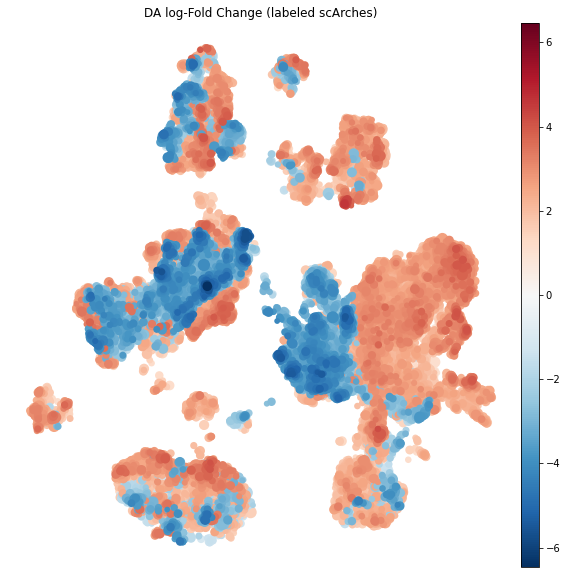

In [93]:
plt.rcParams["figure.figsize"] = [10,10]
milopl.plot_nhood_graph(scarches_labeled, 
                        alpha=0.01, ## SpatialFDR level (1%) 
                        min_size=2, ## Size of smallest dot
                        title="DA log-Fold Change (labeled scArches)"
                       )

In [94]:
milopy.utils.annotate_nhoods(scarches_labeled, anno_col='scanvi_label')

Text(0.5, 0, 'celltype fraction')

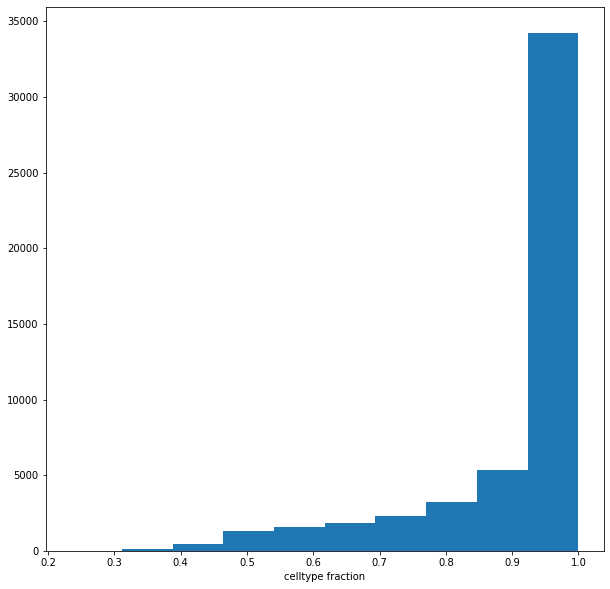

In [95]:
plt.hist(scarches_labeled.uns['nhood_adata'].obs["nhood_annotation_frac"]);
plt.xlabel("celltype fraction")

In [96]:
scarches_labeled.uns['nhood_adata'].obs.loc[scarches_labeled.uns['nhood_adata'].obs["nhood_annotation_frac"] < 0.6, "nhood_annotation"] = "Mixed"

... storing 'nhood_annotation' as categorical


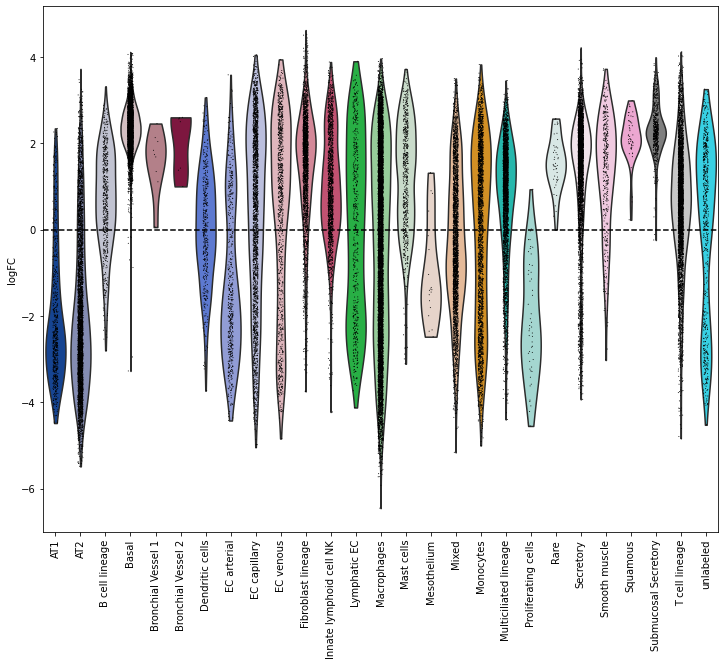

In [97]:
sc.pl.violin(scarches_labeled.uns['nhood_adata'], "logFC", groupby="nhood_annotation", rotation=90, show=False);
plt.axhline(y=0, color='black', linestyle='--');
plt.show()

# 4. De-Novo with reference HVGs

In [98]:
denovo_ref.obs["origin"] = "reference"
denovo_ref.obs.loc[denovo_ref.obs.study.isin(query_studies),"origin"] = "query"

In [99]:
denovo_ref.obs = denovo_ref.obs.loc[:,["sample","study","dataset","origin","scanvi_label"]]

In [100]:
sc.pp.neighbors(denovo_ref, n_neighbors=50, n_pcs=30, use_rep="X_scANVI")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:11:08)


In [101]:
sc.tl.umap(denovo_ref)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:29:13)


... storing 'origin' as categorical
... storing 'highly_variable_intersection-0' as categorical


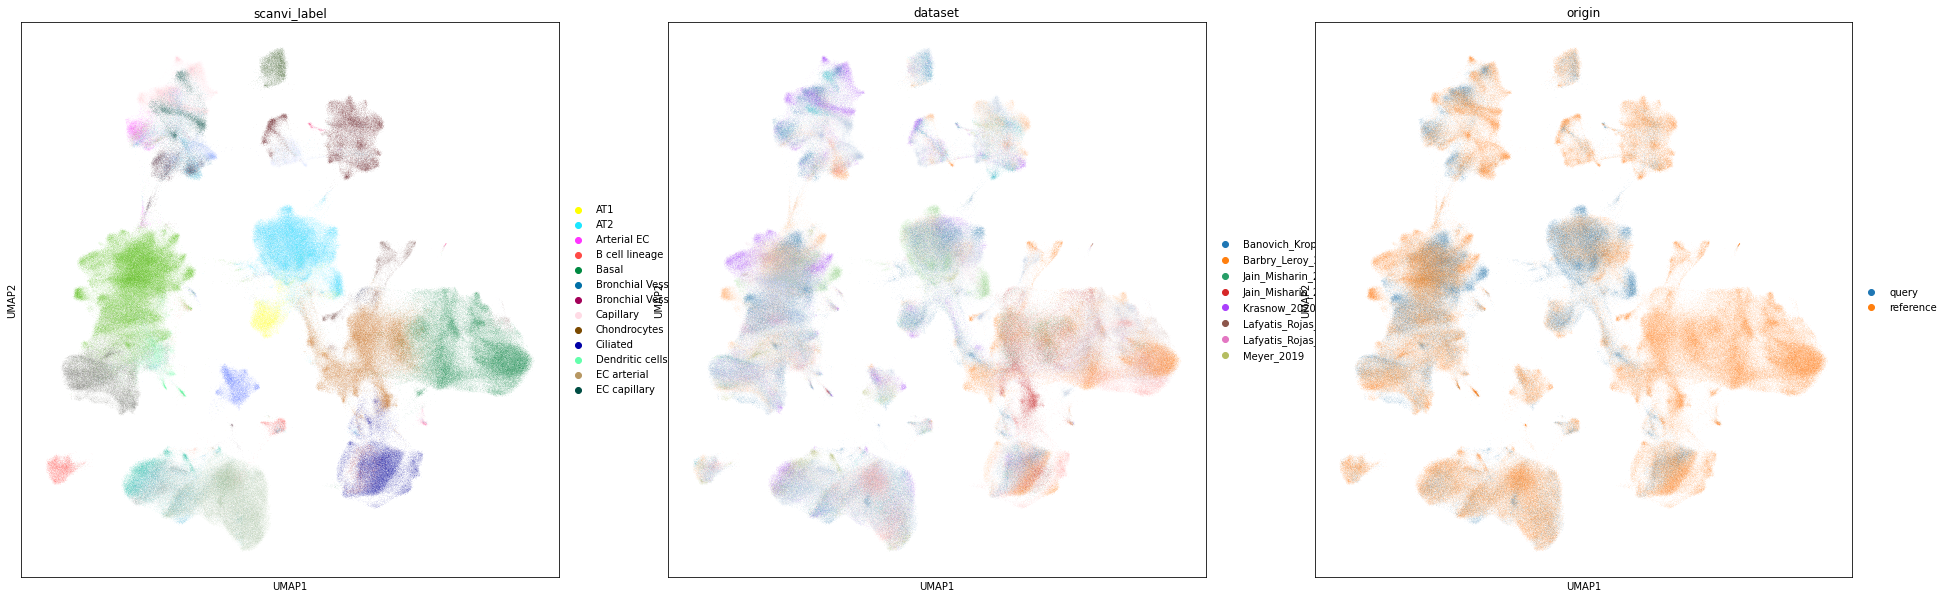

In [102]:
sc.pl.umap(denovo_ref, color=["scanvi_label","dataset", "origin"])

In [103]:
milo.make_nhoods(denovo_ref, prop=0.1)

In [104]:
denovo_ref.obsm["nhoods"]

<713512x50194 sparse matrix of type '<class 'numpy.float32'>'
	with 6106643 stored elements in Compressed Sparse Row format>

In [105]:
denovo_ref[denovo_ref.obs['nhood_ixs_refined'] != 0].obs[['nhood_ixs_refined', 'nhood_kth_distance']]

,nhood_ixs_refined,nhood_kth_distance
CCCAGTTCATACCATG_SC24-0,1,2.135584
CTACCCAAGGCTCTCG_SC85-0,1,1.159113
AGTTGGTTCGGCCGAT_F01641-0,1,1.272324
TCTCATATCTAGAGTC-1-HCATisStab7747198-0,1,1.457680
TAAGTGCCAATACGCT_GRO-03_biopsy-0,1,1.341741
...,...,...
TTGCCGTGTTCAACCA-HCATisStab7732262-1,1,1.918492
TTGGAACAGCTTATCG-HCATisStab7732262-1,1,1.109411
TTGGCAAAGACTTTCG-HCATisStab7732262-1,1,1.477522
TTTCCTCGTCTTGATG-HCATisStab7732262-1,1,1.222643


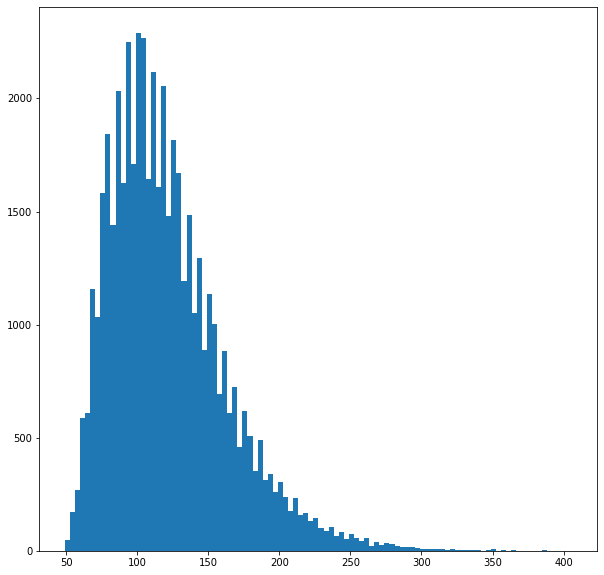

In [106]:
nhood_size = np.array(denovo_ref.obsm["nhoods"].sum(0)).ravel()
plt.hist(nhood_size, bins=100);

In [107]:
milo.count_nhoods(denovo_ref, sample_col="sample")

In [108]:
denovo_ref.uns["nhood_adata"]

AnnData object with n_obs × n_vars = 50194 × 225
    obs: 'index_cell', 'kth_distance'
    uns: 'sample_col'

In [109]:
denovo_ref.obs["origin_continuous"] = denovo_ref.obs["origin"].cat.codes

In [110]:
milo.DA_nhoods(denovo_ref, design="~origin_continuous")

In [111]:
denovo_ref.uns["nhood_adata"].obs

,index_cell,kth_distance,logFC,logCPM,F,PValue,FDR,SpatialFDR
0,CCCAGTTCATACCATG_SC24-0,2.135584,-2.403858,7.195706,28.983330,1.252639e-07,3.216441e-07,3.128472e-07
1,CTACCCAAGGCTCTCG_SC85-0,1.159113,-0.888360,6.925172,4.911635,2.724338e-02,3.727049e-02,3.704610e-02
2,AGTTGGTTCGGCCGAT_F01641-0,1.272324,-2.690835,7.376004,32.362245,2.488304e-08,7.042455e-08,6.778774e-08
3,TCTCATATCTAGAGTC-1-HCATisStab7747198-0,1.457680,1.157536,7.237111,4.504535,2.053411e-01,2.468126e-01,2.456258e-01
4,TAAGTGCCAATACGCT_GRO-03_biopsy-0,1.341741,2.429850,7.049646,36.676913,3.610637e-09,1.205483e-08,1.142980e-08
...,...,...,...,...,...,...,...,...
50189,TTGCCGTGTTCAACCA-HCATisStab7732262-1,1.918492,-2.452716,7.470964,24.218533,1.263316e-06,2.835401e-06,2.785297e-06
50190,TTGGAACAGCTTATCG-HCATisStab7732262-1,1.109411,0.617192,7.142190,1.598646,2.068378e-01,2.484925e-01,2.473129e-01
50191,TTGGCAAAGACTTTCG-HCATisStab7732262-1,1.477522,0.404629,7.143092,0.623536,4.302083e-01,4.869078e-01,4.852012e-01
50192,TTTCCTCGTCTTGATG-HCATisStab7732262-1,1.222643,2.872326,7.226315,33.524078,1.433177e-08,4.211763e-08,4.038396e-08


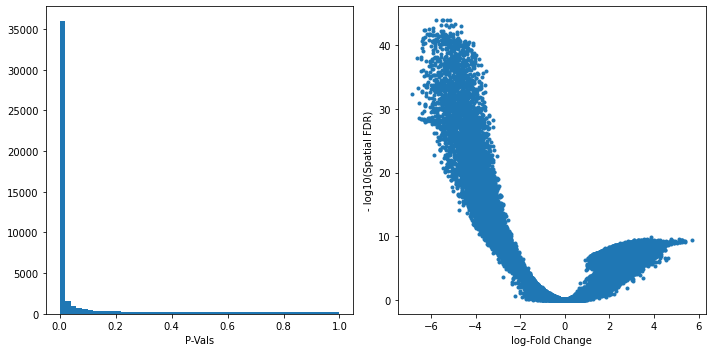

In [112]:
old_figsize = plt.rcParams["figure.figsize"]
plt.rcParams["figure.figsize"] = [10,5]
plt.subplot(1,2,1)
plt.hist(denovo_ref.uns["nhood_adata"].obs.PValue, bins=50);
plt.xlabel("P-Vals");
plt.subplot(1,2,2)
plt.plot(denovo_ref.uns["nhood_adata"].obs.logFC, -np.log10(denovo_ref.uns["nhood_adata"].obs.SpatialFDR), '.');
plt.xlabel("log-Fold Change");
plt.ylabel("- log10(Spatial FDR)");
plt.tight_layout()
plt.rcParams["figure.figsize"] = old_figsize

In [113]:
import milopy.utils
milopy.utils.build_nhood_graph(denovo_ref)

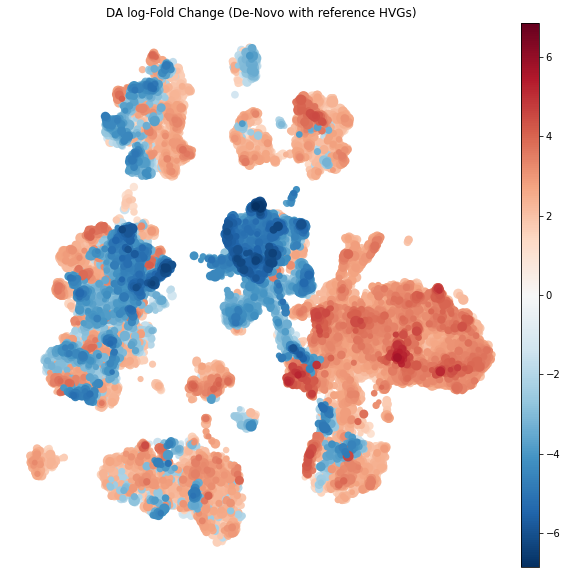

In [119]:
plt.rcParams["figure.figsize"] = [10,10]
milopl.plot_nhood_graph(denovo_ref, 
                        alpha=0.01, ## SpatialFDR level (1%) 
                        min_size=2, ## Size of smallest dot
                        title="DA log-Fold Change (De-Novo with reference HVGs)"
                       )

In [115]:
milopy.utils.annotate_nhoods(denovo_ref, anno_col='scanvi_label')

Text(0.5, 0, 'celltype fraction')

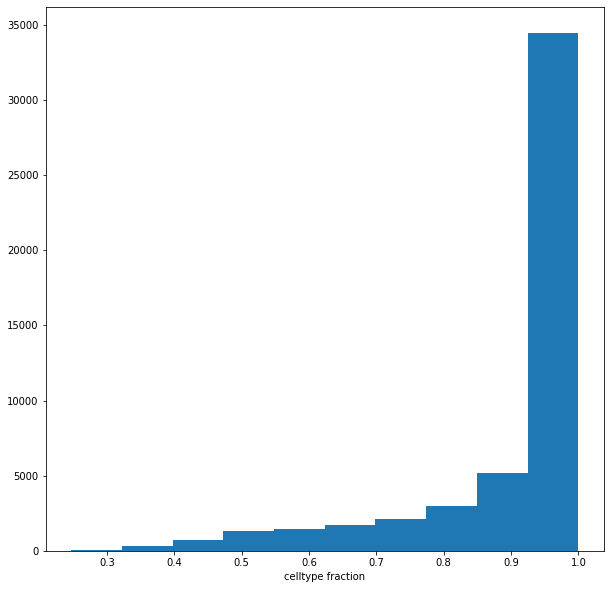

In [116]:
plt.hist(denovo_ref.uns['nhood_adata'].obs["nhood_annotation_frac"]);
plt.xlabel("celltype fraction")

In [117]:
denovo_ref.uns['nhood_adata'].obs.loc[denovo_ref.uns['nhood_adata'].obs["nhood_annotation_frac"] < 0.6, "nhood_annotation"] = "Mixed"

... storing 'nhood_annotation' as categorical


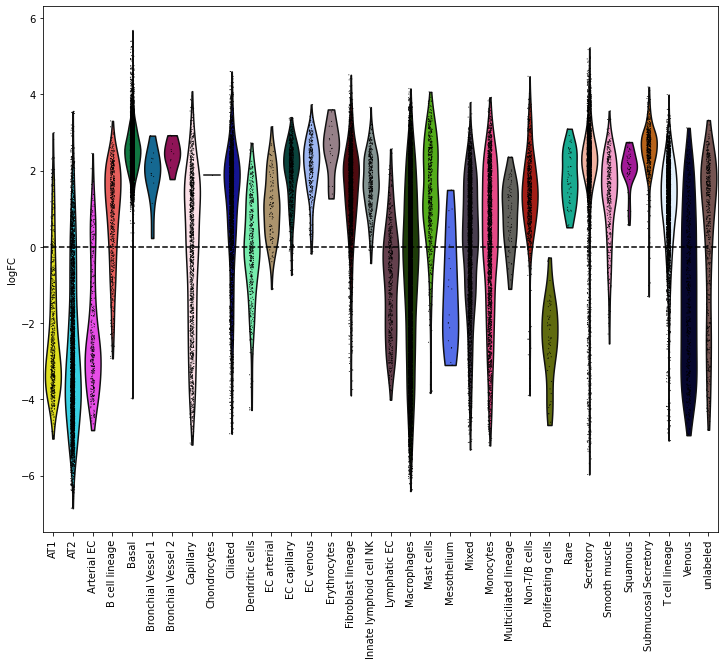

In [118]:
sc.pl.violin(denovo_ref.uns['nhood_adata'], "logFC", groupby="nhood_annotation", rotation=90, show=False);
plt.axhline(y=0, color='black', linestyle='--');
plt.show()